# 09 Fast vector search
To find similar products, I compare one product with all the others. That is fine for 29,500 products, but a bigger catalogue needs a faster way. In this notebook I time the exact search first, then compare fast **approximate nearest-neighbour** indexes with it: FAISS HNSW, FAISS IVF and Annoy. I also use the fast index inside my hybrid search. Nothing here uses the 20 locked final products.

In [1]:
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(root)  # the project reads data/archive.zip relative to the project folder
sys.path.insert(0, str(root / "experiments"))
plt.rcParams.update({"figure.figsize": (9, 3.6), "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

results = root / "results"
base = json.loads((results / "ann_exact_baseline.json").read_text(encoding="utf-8"))
bench = json.loads((results / "ann_benchmark.json").read_text(encoding="utf-8"))
check = json.loads((results / "ann_hybrid_check.json").read_text(encoding="utf-8"))
print("loaded the saved results")

loaded the saved results


## 1. How I measured
The same rule for every method, so that the numbers can be compared:

| What | Rule |
|---|---|
| Test products | 1,000 random products, picked with seed 2020, never a locked product and never one of my 30 development products |
| Time | Each product is searched 5 times and the fastest run is kept. The time shown is the median of the 1,000 |
| Recall@10 | The average over the same 1,000 products: how many of the exact top 10 the method also found |
| Exact top 10 | Brute-force cosine similarity against all other products. Ties are ordered by row number, and a different tie member is not counted as a miss |
| Setup | One thread, one query at a time, so that a single request is what is timed |

In [2]:
try:
    import faiss
    faiss_version = faiss.__version__
except ImportError:
    faiss_version = "not installed here"
print("machine:", base["machine"])
print("numpy:", base["numpy"], "| faiss:", faiss_version, "| k:", base["k"])

machine: macOS-26.2-arm64-arm-64bit
numpy: 2.0.2 | faiss: 1.13.0 | k: 10


## 2. The baseline: the exact search
For each query product, the search multiplies its vector with all the others (cosine similarity, because all vectors have length 1) and keeps the 10 highest scores. This is the code that is timed:

```python
scores = matrix[rows] @ matrix.T                  # cosine similarity with every product
scores[np.arange(len(rows)), rows] = -np.inf      # leave out the product itself
top = np.argpartition(-scores, pool, axis=1)      # the best few
# order them by score, ties by row number, and keep k = 10
```
The full code is `exact_top_k` in `src/product_similarity/vector_search.py`, and the timing loop is in `experiments/ann_exact_baseline.py`.

In [3]:
rows = []
for name, info in base["spaces"].items():
    q = info["queries"]["random1000"]
    rows.append(
        {
            "vectors": name,
            "products searched": f"{info['products']:,}",
            "numbers per vector": info["dimensions"],
            "memory (MB)": info["memory_mb"],
            "time per query, median (ms)": q["one_query_median_ms"],
            "95th percentile (ms)": q["one_query_p95_ms"],
        }
    )
display(pd.DataFrame(rows).set_index("vectors"))

,products searched,numbers per vector,memory (MB),"time per query, median (ms)",95th percentile (ms)
vectors,,,,,
sentence,"29,509",384,45.3,0.85,0.93
picture,"29,366",512,60.1,1.50,1.61


### What this shows
The exact search takes about 0.85 ms for the sentence vectors and about 1.5 ms for the picture vectors. The picture vectors take longer because they have 512 numbers each, and the sentence vectors have 384. The JSON file `results/ann_exact_baseline.json` holds these numbers.

## 3. The fast methods
- **FAISS Flat** is the exact search done by the FAISS library. It is the reference.
- **FAISS HNSW** links each product to its close neighbours in a graph. A search walks along the links toward the query (Malkov and Yashunin, 2018). I tried `M` = 16 and 32, and a search depth `efSearch` from 16 to 256.
- **FAISS IVF** splits the products into 171 groups. A search looks only at the nearest groups, `nprobe` = 1, 4, 16 or 32 of them.
- **Annoy** (from Spotify) builds many random trees. A search follows each tree. I tried 10, 50 and 100 trees and three search depths.

In [4]:
def table(space):
    df = pd.DataFrame(bench["spaces"][space]["indexes"])
    keep = ["index", "M", "efSearch", "nlist", "nprobe", "n_trees", "search_k", "build_seconds", "index_mb", "ms_per_query", "recall_at_10"]
    return df[[c for c in keep if c in df.columns]].fillna("")

for space in ("sentence", "picture"):
    print(f"--- {space} vectors: every setting I tried ---")
    display(table(space))

--- sentence vectors: every setting I tried ---


,index,M,efSearch,nlist,nprobe,n_trees,search_k,build_seconds,index_mb,ms_per_query,recall_at_10
0,faiss_flat,,,,,,,0.00,45.3,0.861,1.0000
1,faiss_hnsw,16.0,16.0,,,,,6.39,49.6,0.014,0.9727
2,faiss_hnsw,16.0,32.0,,,,,6.39,49.6,0.020,0.9824
3,faiss_hnsw,16.0,64.0,,,,,6.39,49.6,0.033,0.9904
4,faiss_hnsw,16.0,128.0,,,,,6.39,49.6,0.063,0.9920
5,faiss_hnsw,16.0,256.0,,,,,6.39,49.6,0.142,0.9929
6,faiss_hnsw,32.0,16.0,,,,,6.75,53.4,0.017,0.9792
7,faiss_hnsw,32.0,32.0,,,,,6.75,53.4,0.024,0.9901
8,faiss_hnsw,32.0,64.0,,,,,6.75,53.4,0.039,0.9940
9,faiss_hnsw,32.0,128.0,,,,,6.75,53.4,0.072,0.9961


--- picture vectors: every setting I tried ---


,index,M,efSearch,nlist,nprobe,n_trees,search_k,build_seconds,index_mb,ms_per_query,recall_at_10
0,faiss_flat,,,,,,,0.01,60.1,1.135,1.0000
1,faiss_hnsw,16.0,16.0,,,,,6.96,64.4,0.018,0.9735
2,faiss_hnsw,16.0,32.0,,,,,6.96,64.4,0.026,0.9922
3,faiss_hnsw,16.0,64.0,,,,,6.96,64.4,0.043,0.9971
4,faiss_hnsw,16.0,128.0,,,,,6.96,64.4,0.078,0.9984
5,faiss_hnsw,16.0,256.0,,,,,6.96,64.4,0.161,0.9990
6,faiss_hnsw,32.0,16.0,,,,,7.36,68.1,0.021,0.9823
7,faiss_hnsw,32.0,32.0,,,,,7.36,68.1,0.031,0.9942
8,faiss_hnsw,32.0,64.0,,,,,7.36,68.1,0.050,0.9976
9,faiss_hnsw,32.0,128.0,,,,,7.36,68.1,0.089,0.9983


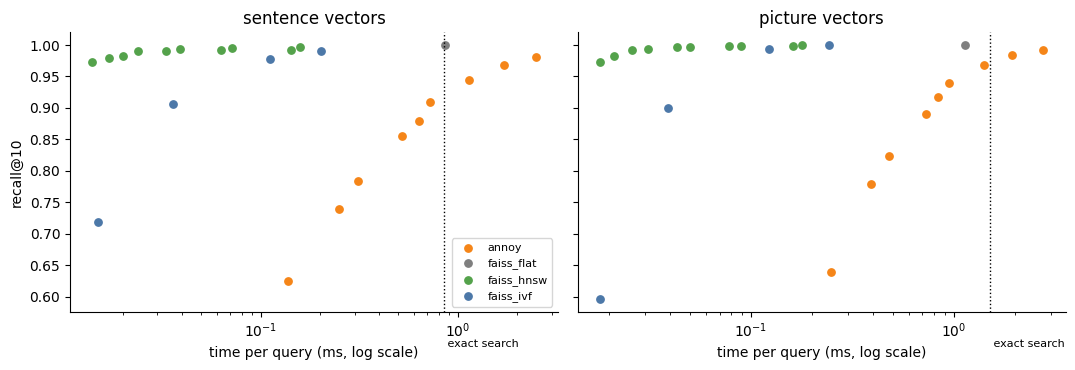

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
colours = {"faiss_flat": "#7f7f7f", "faiss_hnsw": "#54a24b", "faiss_ivf": "#4c78a8", "annoy": "#f58518"}
for ax, space in zip(axes, ("sentence", "picture")):
    df = pd.DataFrame(bench["spaces"][space]["indexes"])
    for method, group in df.groupby("index"):
        ax.scatter(group["ms_per_query"], group["recall_at_10"], label=method, color=colours[method], s=28)
    exact = base["spaces"][space]["queries"]["random1000"]["one_query_median_ms"]
    ax.axvline(exact, color="black", linestyle=":", linewidth=1)
    ax.text(exact, 0.52, " exact search", fontsize=8)
    ax.set_xscale("log")
    ax.set_xlabel("time per query (ms, log scale)")
    ax.set_title(f"{space} vectors")
axes[0].set_ylabel("recall@10")
axes[0].legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

### What this shows
HNSW is the fastest by far: about 0.014 ms for the sentence vectors and 0.018 ms for the picture vectors, which is about 60 times faster than the exact search, and it still finds about 97% of the exact top 10. More search depth gives more recall (up to 99.9% for the picture vectors) at the price of time. IVF is about 8 times faster with a recall of 98% to 99%. Annoy needs many trees and a deep search to reach 97%, and then it is no faster than the exact search at this size. HNSW and Annoy also need an index, which takes 6 to 7 seconds (HNSW) or 2 to 4 seconds (Annoy) to build and a little more memory.

### All methods side by side: time, memory and recall
For each method, its fastest setting that still finds at least 95% of the exact top 10 (the exact search itself is the reference). Memory is the size of the vectors or of the index, in MB. The build time is what it takes to prepare the index once.

In [6]:
rows = []
for space in ("sentence", "picture"):
    exact = base["spaces"][space]
    rows.append({"vectors": space, "method": "exact search (NumPy)", "setting": "", "build (s)": 0.0,
                 "memory (MB)": exact["memory_mb"], "time per query (ms)": exact["queries"]["random1000"]["one_query_median_ms"], "recall@10": 1.0})
    df = pd.DataFrame(bench["spaces"][space]["indexes"])
    for method, group in df.groupby("index", sort=False):
        good = group[group["recall_at_10"] >= 0.95]
        best = (good if len(good) else group).sort_values("ms_per_query").iloc[0]
        setting = ", ".join(f"{k}={int(best[k])}" for k in ("M", "nlist", "n_trees", "efSearch", "nprobe", "search_k") if k in best and best[k] == best[k])
        rows.append({"vectors": space, "method": method, "setting": setting, "build (s)": best["build_seconds"],
                     "memory (MB)": best["index_mb"], "time per query (ms)": best["ms_per_query"], "recall@10": best["recall_at_10"]})
display(pd.DataFrame(rows).set_index(["vectors", "method"]))

setting  build (s)  memory (MB)  time per query (ms)  recall@10
vectors  method                                                                                                  
sentence exact search (NumPy)                                   0.00         45.3                0.850     1.0000
         faiss_flat                                             0.00         45.3                0.861     1.0000
         faiss_hnsw                     M=16, efSearch=16       6.39         49.6                0.014     0.9727
         faiss_ivf                   nlist=171, nprobe=16       0.13         45.8                0.111     0.9771
         annoy                 n_trees=50, search_k=11000       1.79         67.1                1.710     0.9675
picture  exact search (NumPy)                                   0.00         60.1                1.500     1.0000
         faiss_flat                                             0.01         60.1                1.135     1.0000
         faiss_hnsw                     M=16, efSearch=16       6.96         64.4                0.018     0.9735
         faiss_ivf                   nlist=171, nprobe=16       0.18         60.7                0.122     0.9931
         annoy                 n_trees=100, search_k=5500       4.03        104.9                1.411     0.9685

## 4. The fast index inside the hybrid search
A fast index works on one vector per product, but my hybrid also uses category, brand, price and the other attributes. So I use both:
1. The index holds one combined vector for each product: the sentence vector and the picture vector, scaled by the square roots of their weights in the final 4-weight hybrid (46% and 29%). The dot product of two combined vectors is then the weighted sum of the two cosines.
2. For a product, the index returns 200 candidates.
3. The hybrid scores only those 200 with all ten parts and takes the final 10.

I compare the final 10 with the normal hybrid, which scores all products. For nDCG@10 I use my ratings, for the 30 development products. The hybrid weights were tuned on the same products, so the numbers are best read as a comparison between the rows.

In [7]:
rows = [
    {
        "pipeline": "exact hybrid (scores all products)",
        "nDCG@10": check["exact_hybrid_ndcg_at_10"],
        "top 10 shared with the exact hybrid": 1.0,
        "time (ms)": check["exact_hybrid_ms_per_query"],
    }
]
for r in check["results"]:
    rows.append(
        {
            "pipeline": f"{r['candidates_from']} picks {r['candidates']} candidates, then the hybrid",
            "nDCG@10": r["ndcg_at_10"],
            "top 10 shared with the exact hybrid": r["overlap_with_exact_hybrid_at_10"],
            "time (ms)": r["candidate_search_ms"],
        }
    )
display(pd.DataFrame(rows).set_index("pipeline"))
print("time = scoring all products for the exact hybrid, and only the candidate search for the others")

,nDCG@10,top 10 shared with the exact hybrid,time (ms)
pipeline,,,
exact hybrid (scores all products),0.8083,1.0000,6.280
"hnsw picks 50 candidates, then the hybrid",0.7692,0.9133,0.066
"hnsw picks 100 candidates, then the hybrid",0.7819,0.9400,0.065
"hnsw picks 200 candidates, then the hybrid",0.7844,0.9433,0.073
"hnsw picks 500 candidates, then the hybrid",0.7844,0.9433,0.101
"exact_vectors picks 50 candidates, then the hybrid",0.7913,0.9300,1.989
"exact_vectors picks 100 candidates, then the hybrid",0.8032,0.9600,2.007
"exact_vectors picks 200 candidates, then the hybrid",0.8071,0.9700,2.036
"exact_vectors picks 500 candidates, then the hybrid",0.8091,0.9700,2.109


time = scoring all products for the exact hybrid, and only the candidate search for the others


### What this shows
With 200 candidates from HNSW, the final top 10 shares 94% with the exact hybrid, and nDCG@10 is 0.784 against 0.808. The loss comes from the candidates that the index misses: when the candidates come from an exact search, nDCG@10 is 0.807. More candidates help a little, and 500 gave the same result as 200. The exact hybrid takes 6.3 ms per product, and the HNSW candidate search takes 0.07 ms. I did not time the reranking of the 200 candidates.

## 5. Recorded in MLflow
I used MLflow to keep a record of every run, the same way as in the other notebooks. Each setting of each method is one run in the experiment `ann-benchmark`: 50 runs in all. A run stores its settings (for example `M` and `efSearch` for HNSW), its results (time per query, recall@10, build time and index size), the rule in a tag, and the JSON file as an attachment. The runs tagged `headline = yes` are the exact search and, for each method, its fastest setting that still finds at least 95% of the exact top 10. This is MLflow's comparison page for those ten runs (sentence vectors on the left, picture vectors on the right):

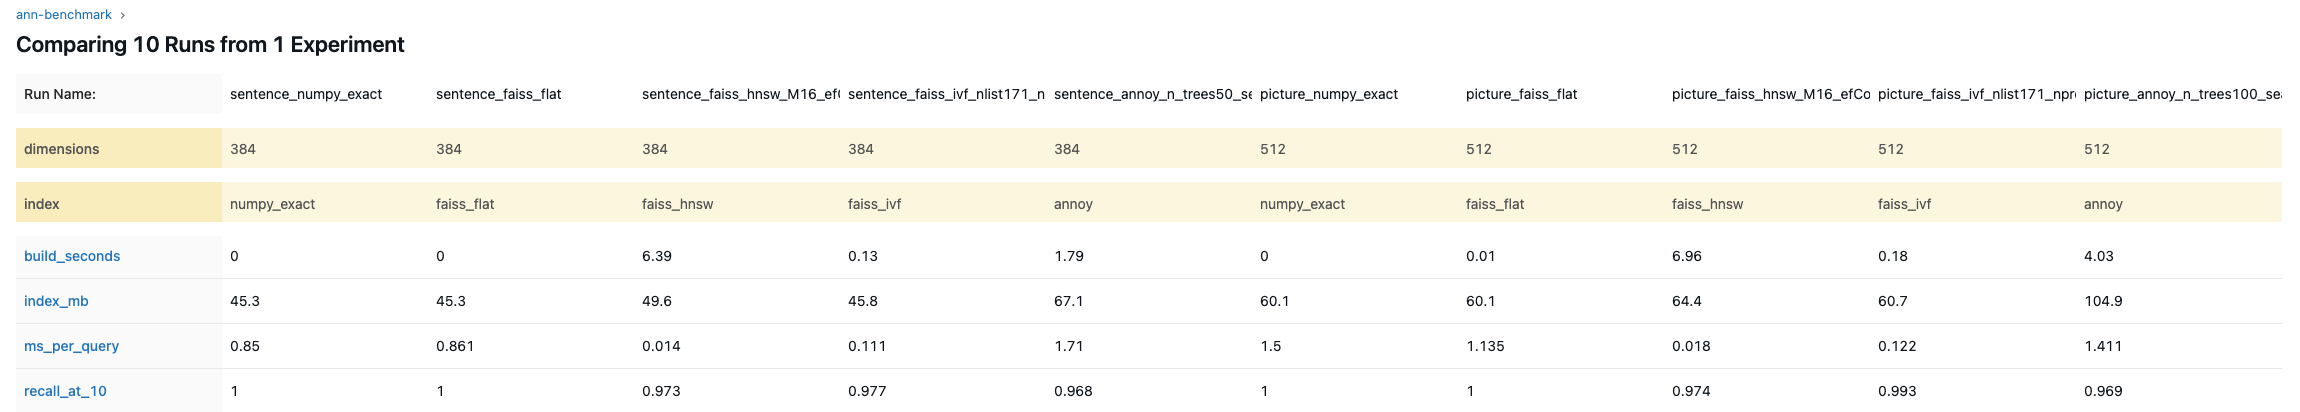

In [8]:
from IPython.display import Image

Image(filename=root / "evaluation" / "mlflow_ann_benchmark_runs.png", width=1000)

The hybrid check is a second experiment, `ann-hybrid-check`, with one run for each pipeline:

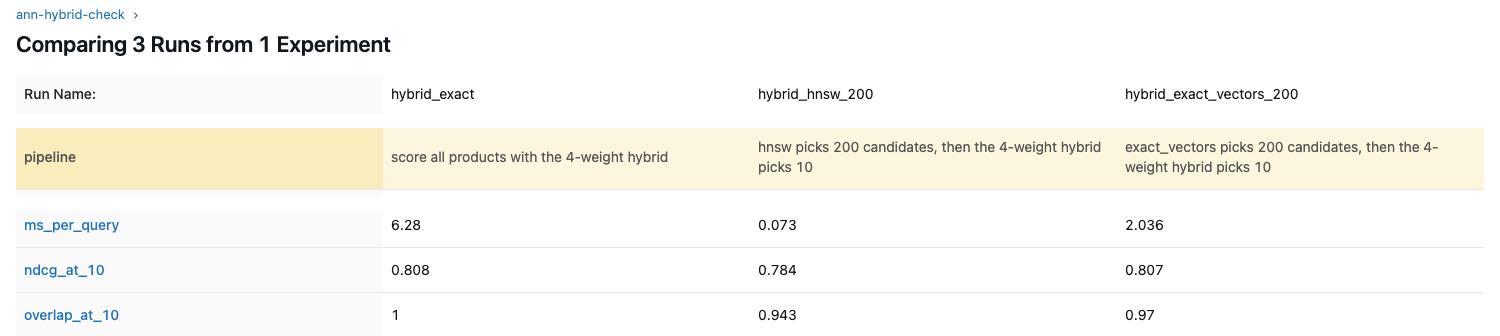

In [9]:
Image(filename=root / "evaluation" / "mlflow_ann_hybrid_runs.png", width=900)

References: Malkov and Yashunin, [Efficient and robust approximate nearest neighbor search using Hierarchical Navigable Small World graphs](https://arxiv.org/abs/1603.09320) (HNSW); Johnson, Douze and Jégou, [Billion-scale similarity search with GPUs](https://arxiv.org/abs/1702.08734) (FAISS); [Annoy](https://github.com/spotify/annoy) from Spotify.

## 6. Conclusion

**What I wanted to know:** can I make the similarity search faster without losing much quality, and does it matter at my size?

**What I did.** I used one rule for every method. I took 1,000 random products, picked with seed 2020 and never a locked product. For each product I ran the search 5 times and kept the fastest run, and I report the median time of the 1,000. Recall@10 is the average over the same 1,000 products. I counted how many of the exact top 10 each fast method found. The exact top 10 comes from the brute-force search, which compares a product with all the others by cosine similarity. I tried FAISS HNSW, FAISS IVF and Annoy on the picture vectors (CLIP) and on the sentence vectors. I recorded every setting in MLflow, one run for each. Then I used the fast index inside my hybrid search: the index picks 200 candidates, and the hybrid with 4 weights picks the final 10.

| Method (sentence vectors, 384 numbers) | Time per query | Memory | Recall@10 |
|---|---|---|---|
| Exact search (brute force) | 0.85 ms | 45.3 MB | 100% |
| FAISS HNSW | 0.014 ms | 49.6 MB | 97% |
| FAISS IVF | 0.11 ms | 45.8 MB | 98% |
| Annoy | 1.7 ms | 67.1 MB | 97% |

| Method (picture vectors, 512 numbers) | Time per query | Memory | Recall@10 |
|---|---|---|---|
| Exact search (brute force) | 1.5 ms | 60.1 MB | 100% |
| FAISS HNSW | 0.018 ms | 64.4 MB | 97% |
| FAISS IVF | 0.12 ms | 60.7 MB | 99% |
| Annoy | 1.4 ms | 104.9 MB | 97% |

For each fast method I show its fastest setting that still finds at least 95% of the exact top 10.

| Hybrid with the fast index | nDCG@10 | Top 10 shared with the exact hybrid |
|---|---|---|
| Exact hybrid (scores all products, 6.3 ms) | 0.808 | 100% |
| HNSW picks 200 candidates, then the hybrid (0.07 ms for the candidates) | 0.784 | 94% |
| Exact search picks 200 candidates, then the hybrid | 0.807 | 97% |

**What I found**

- The exact search is already fast at my size: about 1 ms for one product among 29,500, with 45 to 60 MB of memory.
- HNSW is about 60 times faster than the exact search and still finds 97% of the exact top 10. It needs about 10% more memory and 6 to 7 seconds to build. IVF is about 8 times faster with almost no extra memory. Annoy was not faster than the exact search at this size and needs more memory.
- Inside the hybrid, the fast index costs a little quality: nDCG@10 goes from 0.808 to 0.784 with HNSW. The cost comes from the candidates it misses, because exact candidates lose almost nothing (0.807).
- I chose HNSW (Malkov and Yashunin, 2018) because it gave the best speed for the recall.

**What I can't say yet**

- I tested only about 29,500 products. At this size the exact search is already fast, so the gain from a fast index will matter more for a much larger catalogue. I did not test that.
- The timings are from one laptop, one thread, one query at a time. I did not time the final reranking of the 200 candidates with the hybrid.

**What I do next.** I test whether shortening the vectors with PCA helps the memory and the speed (notebook 10).